# AACR Project GENIE v20.0-public — questions V1–V4 (ALK-altered patients)

Source: Jacob's *CBIO thoughts* deck, slides 28–31. Data: GENIE v20.0-public main release (Synapse): clinical patient / sample tables,
mutations, discrete CNA, structural variants, and the gene panel files. No treatment data.

**What survival means here (V1).** GENIE releases, per patient, the interval from birth to death (`INT_DOD`) or to last contact
(`INT_CONTACT`), and per sample the age at the sequencing report. The only index date available for every patient is therefore the
**sequencing report**, and the derived endpoint is *OS from sequencing* = (INT_DOD or INT_CONTACT) − age at sequencing report.
Diagnosis date cannot be inferred from age at sequencing. Intervals are censored at age > 89 or < 18 (kept at the boundary and flagged).
Because every patient enters at sequencing, this endpoint is not left-truncated, but it is strongly affected by *when* in the disease
course a centre sequences (at diagnosis vs at progression), which differs by centre and era.

Conventions as in `README.md`. **ALK-altered = ALK structural variant / fusion.** The release holds 1,152 samples with an ALK structural variant,
which is the deck's 1,153-sample count; "any ALK alteration" would instead pull in 9,525 samples with ALK point mutations, overwhelmingly passenger
events in hypermutated colorectal, melanoma and endometrial tumours (only a quarter of them lung), plus a few hundred amplifications. ALK point
mutations are kept only as the resistance-mutation footprint in V4. Gene screens require the gene to be on the panel of at least half the cohort,
so genes carried by a single centre's panel cannot dominate, and hazard ratios are adjusted for age, sex and centre.

In [1]:
import sys, re, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "cbio_lib.py").exists())
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import cbio_lib as cb

cb.setup_plots()
warnings.filterwarnings("ignore")
pd.options.display.float_format = "{:.3g}".format
pd.options.display.width = 200
DS = "genie_v20"
F = []

G = cb.GenieMain()
log = pd.read_csv(cb.DATA / "genie" / "download_log.csv")
display(log[log.cohort == "GENIE_main"][[c for c in ["category", "filename", "synapse_id", "version", "md5"] if c in log.columns]])
print(f"patients {len(G.patients):,}, samples {len(G.samples_all):,}")

,category,filename,synapse_id,version,md5
237,docs,data_guide.pdf,syn76285066,1,80dbcce42c83c1d863f0a27085fe9df2
238,docs,release-notes.pdf,syn76285092,1,b5e9ef28ca5b31b4c6e19ddd0cb3a9dc
239,docs,assay_information.txt,syn76285059,1,279b94dafb388fea9c1a96aef39456d0
240,clinical,data_clinical_patient.txt,syn76285062,1,4de7f0cdc0b7c4327f7831b8c650aedf
241,clinical,data_clinical_sample.txt,syn76285063,1,ee7bca033a1070ed469c8cfa2d65c251
...,...,...,...,...,...
414,panel,data_gene_panel_WAKE-CLINICAL-T5A.txt,syn76285814,1,069de0e00ef985ba52991f3212623d53
415,panel,data_gene_panel_WAKE-CLINICAL-T7.txt,syn76285815,1,b13342876e14398c1b26525ba0c31029
416,panel,data_gene_panel_YALE-HSM-V1.txt,syn76285816,1,00fdc505c6750a53ec534b83f2193334
417,panel,data_gene_panel_YALE-OCP-V2.txt,syn76285817,1,c44664b9b852b242ec53fd1755ec6108


patients 242,866, samples 289,869


## ALK-altered samples and patients

In [2]:
alk = G.gene_rows("ALK")
mut_s = set(alk["mut"][alk["mut"].Variant_Classification.isin(cb.NONSYN)].sample_id)
sv_s = set(alk["sv"].Sample_Id) if len(alk["sv"]) else set()
cand = G.samples_all[G.samples_all.sample_id.isin(mut_s | sv_s)]
# CNA for ALK across the release: the full matrix is too large to load, so stream the file and keep only the ALK row
alk_cna = None
with open(G._cna) as fh:
    header = fh.readline().rstrip("\n").split("\t")
    for line in fh:
        if line.startswith("ALK\t"):
            alk_cna = pd.Series(line.rstrip("\n").split("\t")[1:], index=header[1:])
            break
alk_cna = pd.to_numeric(alk_cna, errors="coerce") if alk_cna is not None else pd.Series(dtype=float)
amp_s, del_s = set(alk_cna.index[alk_cna == 2]), set(alk_cna.index[alk_cna == -2])
rows = []
for name, ids in [("structural variant / fusion", sv_s), ("point mutation (any non-synonymous)", mut_s), ("amplification", amp_s), ("deep deletion", del_s),
                  ("any of the above", mut_s | sv_s | amp_s | del_s)]:
    sub = G.samples_all[G.samples_all.sample_id.isin(ids)]
    rows.append(dict(alteration=name, samples=len(sub), patients=sub.patient_id.nunique(), pct_nsclc=round(100 * (sub.CANCER_TYPE == "Non-Small Cell Lung Cancer").mean(), 1)))
display(pd.DataFrame(rows).set_index("alteration"))
alk_samples = G.samples_all[G.samples_all.sample_id.isin(sv_s)].copy()           # the cohort: ALK structural variant / fusion
alk_samples["center"] = alk_samples.patient_id.map(G.patients.CENTER)
print(f"ALK-fusion samples {len(alk_samples):,} from {alk_samples.patient_id.nunique():,} patients (deck: 1,153 samples / 1,274 patients)")
display(alk_samples.CANCER_TYPE.value_counts().head(10).rename("ALK-fusion samples by cancer type"))
display(alk_samples.center.value_counts().rename("ALK-fusion samples by centre"))

,samples,patients,pct_nsclc
alteration,,,
structural variant / fusion,1152,953,68.6
point mutation (any non-synonymous),9525,8911,19.5
amplification,158,149,11.4
deep deletion,53,49,1.9
any of the above,10743,9938,23.7


ALK-fusion samples 1,152 from 953 patients (deck: 1,153 samples / 1,274 patients)


CANCER_TYPE
Non-Small Cell Lung Cancer    790
Soft Tissue Sarcoma            42
Cancer of Unknown Primary      33
Mature T and NK Neoplasms      31
Skin Cancer, Non-Melanoma      25
Thyroid Cancer                 25
Glioma                         22
Colorectal Cancer              19
Pancreatic Cancer              12
Ovarian Cancer                 12
Name: ALK-fusion samples by cancer type, dtype: int64

center
MSK     601
DFCI    283
UCSF    136
PROV     73
VICC     27
DUKE     15
CHOP     11
UHN       6
Name: ALK-fusion samples by centre, dtype: int64

## V1 — Can OS be derived at all?

,step,n,dropped
0,ALK-fusion patients,953,0
1,With vital status (DEAD true/false),883,70
2,With usable interval (last contact / death aft...,772,111
3,… and not censored at an age boundary,752,20


col_0,unusable,usable,All
center,,,
CHOP,2,9,11
DFCI,26,213,239
DUKE,6,9,15
MSK,78,389,467
PROV,19,50,69
UCSF,49,72,121
UHN,0,6,6
VICC,1,24,25
All,181,772,953


ALK-fusion, usable: n=772, deaths 303, median derived OS from sequencing 71.2 months; median age at sequencing 59


BPC NSCLC ALK-fusion patients (n=53): months from diagnosis to sequencing report median 3.4, IQR 1.6-18.0
[V1] feasible with caveats: OS from sequencing report is derivable for 772 of 953 ALK-fusion patients (vital status + intervals released). Diagnosis date cannot be inferred; in BPC NSCLC the diagnosis-to-sequencing lag is months to years and varies by stage. Median derived OS: NSCLC 72.4 mo.


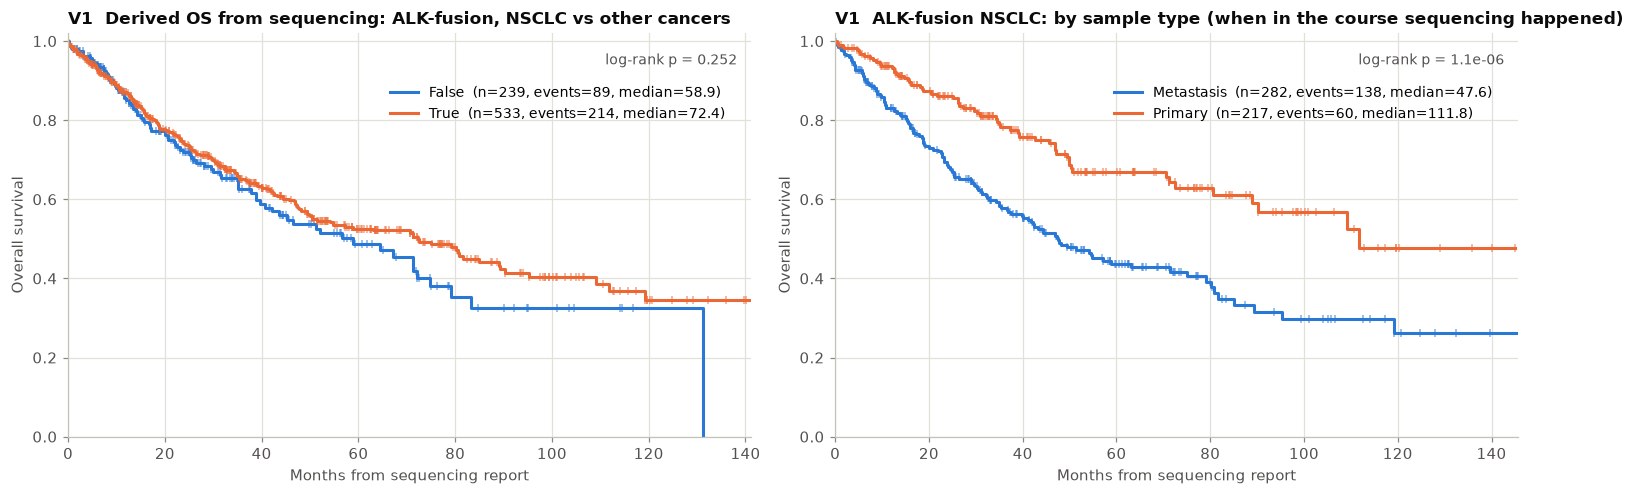

In [3]:
S = G.survival_from_sequencing(alk_samples)
S["nsclc"] = S.cancer_type.eq("Non-Small Cell Lung Cancer")
ok = S.time.notna() & S.event.notna()
display(cb.consort([("ALK-fusion patients", len(S)), ("With vital status (DEAD true/false)", int(S.event.notna().sum())),
                    ("With usable interval (last contact / death after sequencing report)", int(ok.sum())),
                    ("… and not censored at an age boundary", int((ok & ~S.censored_interval).sum()))]))
display(pd.crosstab(S.center, ok, margins=True).rename(columns={False: "unusable", True: "usable"}))
S = S[ok]
print(f"ALK-fusion, usable: n={len(S)}, deaths {int(S.event.sum())}, median derived OS from sequencing {cb.km_table(S.assign(g='all'), 'g').median_months[0]} months; "
      f"median age at sequencing {S.age_seq_years.median():.0f}")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
cb.km_plot(S, "nsclc", ax=axes[0], title="V1  Derived OS from sequencing: ALK-fusion, NSCLC vs other cancers", xlabel="Months from sequencing report", risk_table=False)
cb.km_plot(S[S.nsclc & S.sample_type.isin(["Primary", "Metastasis"])], "sample_type", ax=axes[1], title="V1  ALK-fusion NSCLC: by sample type (when in the course sequencing happened)", xlabel="Months from sequencing report", risk_table=False)
fig.tight_layout()
cb.save(DS, "V1", table=cb.km_table(S, "nsclc"), fig=fig, slug="derived_os_overview")
# how far after diagnosis does sequencing happen? use BPC NSCLC (which has both dates) for ALK+ patients
try:
    bn = cb.BPC("NSCLC"); An = bn.alterations(); alk_bpc = An.status("ALK", "fus"); Sn = bn.survival_dx()
    lag = Sn.loc[alk_bpc.index[alk_bpc], "entry"]
    print(f"BPC NSCLC ALK-fusion patients (n={len(lag)}): months from diagnosis to sequencing report median {lag.median():.1f}, IQR {lag.quantile(.25):.1f}-{lag.quantile(.75):.1f}")
except Exception as e:
    print("BPC NSCLC not available for the diagnosis-to-sequencing lag:", e)
cb.finding("V1", "feasible with caveats",
           f"OS from sequencing report is derivable for {len(S)} of {len(alk_samples.patient_id.unique())} ALK-fusion patients (vital status + intervals released). "
           f"Diagnosis date cannot be inferred; in BPC NSCLC the diagnosis-to-sequencing lag is months to years and varies by stage. "
           f"Median derived OS: NSCLC {cb.km_table(S, 'nsclc').set_index('group').median_months.get(True)} mo.", F)

## V2 — How does OS change with additional mutations in ALK-altered patients?
ALK-fusion NSCLC (one sample per patient, earliest), derived OS from sequencing; every co-alteration with ≥ 10 carriers / non-carriers and the
gene on the panel of ≥ 50% of the cohort; log-rank, Cox HR adjusted for age, sex and centre (five largest centres, rest pooled), BH FDR.

alteration matrix: 626 ALK-fusion NSCLC patients x 1539 genes; unknown panel 0


,feature,gene,kind,n_alt,n_wt,tested_frac,events_alt,events_wt,median_alt,median_wt,p_logrank,HR,HR_lo,HR_hi,p_cox,n_cox,q_bh
0,KMT2D mut,KMT2D,mut,37,497,0.99,24,190,23.2,79,2.43e-05,2.21,1.41,3.45,0.000522,534,0.00136
1,TP53 mut,TP53,mut,166,371,1,83,134,40,80.7,0.000114,1.69,1.28,2.24,0.000219,537,0.00212
2,EGFR mut,EGFR,mut,13,524,1,11,206,16.6,75,0.000156,2.87,1.54,5.37,0.000937,537,0.00219
3,NF2 mut,NF2,mut,13,521,0.99,8,206,22.6,75,0.000716,3.48,1.7,7.13,0.000661,534,0.00802
4,CDKN2A homdel,CDKN2A,homdel,96,356,0.84,45,136,40,80.7,0.00232,1.74,1.23,2.48,0.00194,452,0.0217
5,CDKN2B homdel,CDKN2B,homdel,88,364,0.84,42,139,40,80.7,0.00747,1.63,1.14,2.32,0.00736,452,0.053
6,MTAP homdel,MTAP,homdel,30,422,0.84,12,169,23.2,80.2,0.00758,2.6,1.4,4.84,0.0026,452,0.053
7,ROS1 mut,ROS1,mut,12,525,1,7,210,16.1,72.4,0.0144,2.63,1.21,5.68,0.0142,537,0.0898
8,KDR mut,KDR,mut,11,523,0.99,6,208,32.1,72.5,0.0272,1.52,0.622,3.7,0.36,534,0.152
9,CIC mut,CIC,mut,12,475,0.91,7,185,26.1,71.2,0.0326,1.47,0.656,3.29,0.349,487,0.166


[V2] signal: ALK-fusion NSCLC n=537. FDR<0.1: KMT2D mut (n=37) HR 2.21 q=0.0014, TP53 mut (n=166) HR 1.69 q=0.0021, EGFR mut (n=13) HR 2.87 q=0.0022, NF2 mut (n=13) HR 3.48 q=0.008, CDKN2A homdel (n=96) HR 1.74 q=0.022, CDKN2B homdel (n=88) HR 1.63 q=0.053, MTAP homdel (n=30) HR 2.60 q=0.053, ROS1 mut (n=12) HR 2.63 q=0.09.


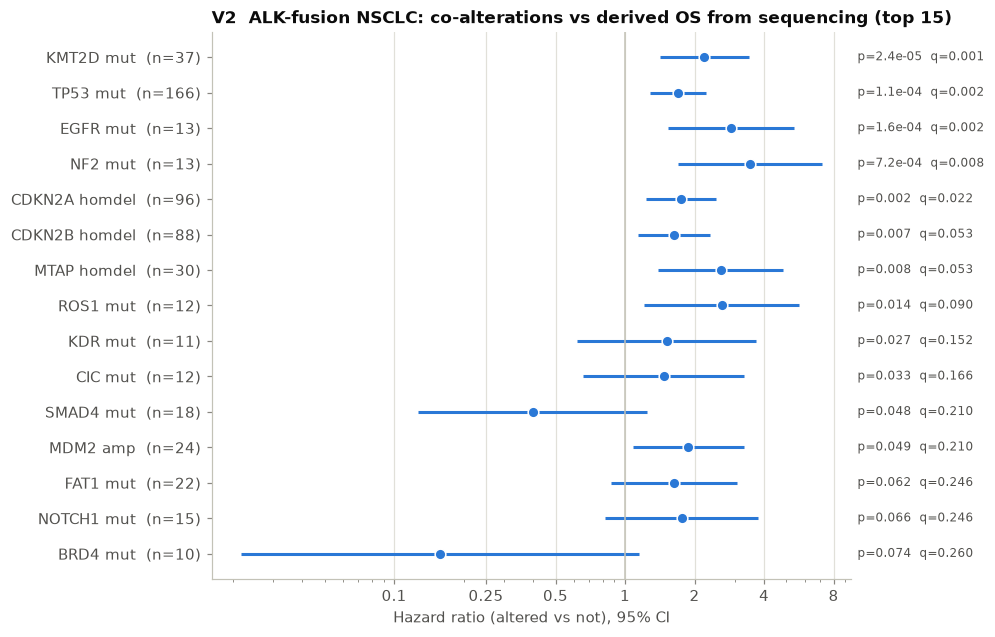

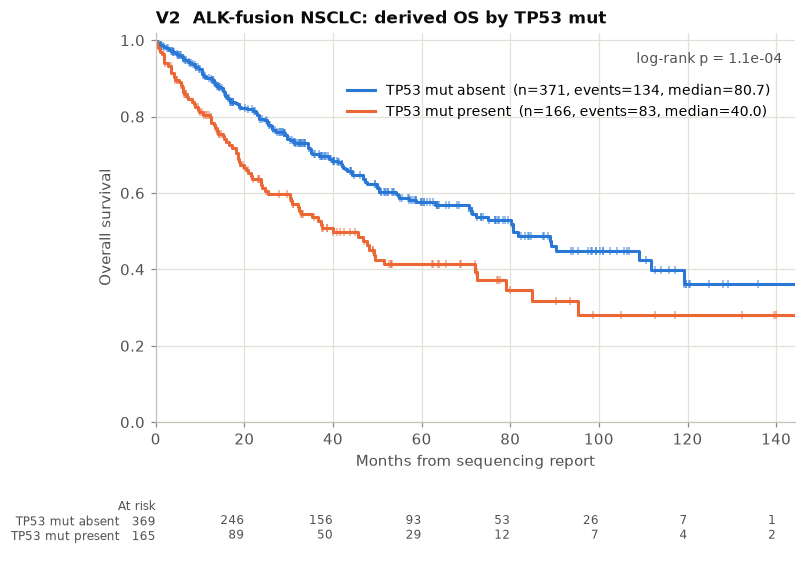

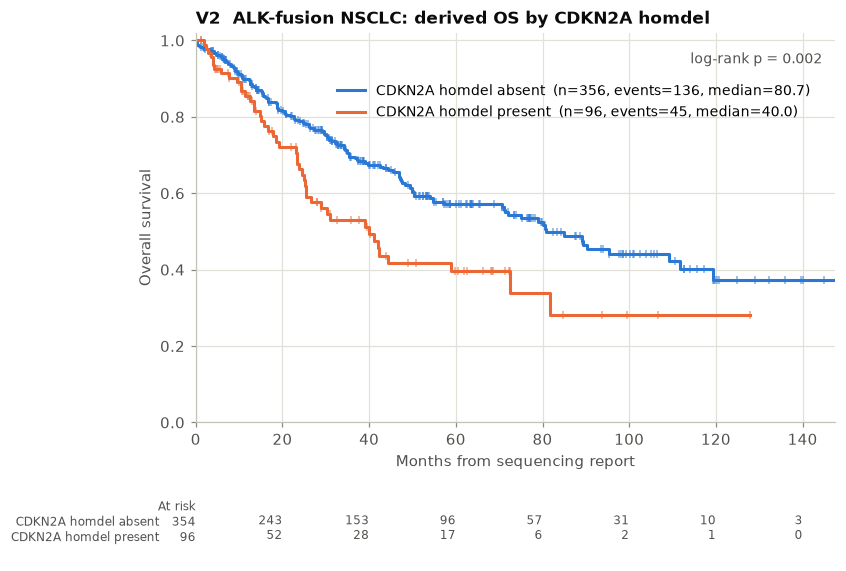

In [4]:
nsclc = alk_samples[alk_samples.CANCER_TYPE == "Non-Small Cell Lung Cancer"].sort_values(["patient_id", "age_seq_days"]).drop_duplicates("patient_id")
A = G.alterations(nsclc[["sample_id", "patient_id"]])
mut_long, cna_long, sv_long = G.last_genomics
print(f"alteration matrix: {len(A.patients)} ALK-fusion NSCLC patients x {len(A.genes)} genes; unknown panel {A.n_unknown_panel}")
Sn = S[S.index.isin(A.patients)].copy()
Sn["age"] = Sn.age_seq_years
top_centers = Sn.center.value_counts().index[:5]
Sn["center_grp"] = Sn.center.where(Sn.center.isin(top_centers), "other")
ADJ = ["age", "sex", "center_grp"]
scr = cb.gene_screen(Sn, A, kinds=("mut", "amp", "homdel", "fus"), min_n=10, adjust=ADJ, min_tested_frac=0.5)
scr = scr[(scr.gene != "ALK") & (scr.feature != "EML4 fus")].reset_index(drop=True)
ax = cb.forest_plot(scr, top=15, title="V2  ALK-fusion NSCLC: co-alterations vs derived OS from sequencing (top 15)")
cb.save(DS, "V2", table=scr, fig=ax.figure, slug="comutation_screen")
display(scr.head(15))
for g, k in [("TP53", "mut"), ("CDKN2A", "homdel")]:
    d, t = cb.compare(Sn, A.status(g, k), labels=(f"{g} {k} absent", f"{g} {k} present"), adjust=ADJ)
    ax, _ = cb.km_plot(d, "group", order=[f"{g} {k} absent", f"{g} {k} present"], title=f"V2  ALK-fusion NSCLC: derived OS by {g} {k}", xlabel="Months from sequencing report")
    cb.save(DS, "V2", table=t, fig=ax.figure, slug=f"by_{g}_{k}")
hits = scr[scr.q_bh < 0.1]
cb.finding("V2", "signal" if len(hits) else "no signal at FDR<0.1",
           f"ALK-fusion NSCLC n={len(Sn)}. FDR<0.1: " +
           (", ".join(f"{r.feature} (n={r.n_alt}) HR {r.HR:.2f} q={r.q_bh:.2g}" for r in hits.itertuples()) or f"none (best {scr.feature[0]} HR {scr.HR[0]:.2f} p={cb.fmt_p(scr.p_logrank[0])})") + ".", F)

## V3 — Full alteration profile of every ALK-altered patient, related to survival
One row per patient with every mutation (protein change), structural variant and ±2 copy-number call; an oncoprint-style view of the
25 most frequent co-alterations in ALK-altered NSCLC, and the example profile from slide 31 (EML4-ALK + TP53 + STAT3 + EPHA3 + ERBB2 amp).

,mutations,structural_variants,copy_number,time,event,cancer_type,oncotree,center,age_seq_years
GENIE-DFCI-000049,ALK p.Q1064R; ATM p.T2438K; GLI3 p.D745N; TP53...,ALK-INTERGENIC,,64,0,Non-Small Cell Lung Cancer,LUAD,DFCI,83.3
GENIE-DFCI-000153,GLI3 p.K13R; SMO p.L23dup,ALK-INTERGENIC; DNMT3A-INTERGENIC,,84.1,0,Non-Small Cell Lung Cancer,IMTL,DFCI,58.7
GENIE-DFCI-000277,APC p.N389S; CSF1R p.R549C; SETD2 p.K1875*; SE...,ALK-EML4,,20.4,1,Non-Small Cell Lung Cancer,LUAD,DFCI,43.4
GENIE-DFCI-001243,ABL1 p.P853A; ALK p.G933A; AXL p.M623R; AXL p....,CLIP4-ALK; NTRK1-INTERGENIC; SBNO2-STK11,EXT1 amp; FGFR1 amp; FOXA1 amp; KAT6A amp; MYB...,19.7,0,Non-Small Cell Lung Cancer,NSCLC,DFCI,62.8
GENIE-DFCI-001671,DMD p.A1901T; FLT4 p.R1031*; MET p.G471E; NTRK...,EML4-ALK,,140,0,Non-Small Cell Lung Cancer,NSCLC,DFCI,52.9
GENIE-DFCI-002383,APC p.P2261L; ERBB3 p.G821V; FLT3 p.G48E; GSTM...,ALK-EML4,CDKN2A homdel; CDKN2B homdel; PTEN homdel,42.3,1,Non-Small Cell Lung Cancer,NSCLCPD,DFCI,62.9
GENIE-DFCI-002429,ARID2 p.H323Y; KDM6A p.Q333*,ALK-EML4,,44.4,1,Non-Small Cell Lung Cancer,LUAD,DFCI,68.5
GENIE-DFCI-002576,BAP1 p.G470R; BRCA2 p.L759V; BRCA2 p.Y761C; JA...,EML4-ALK,,114,0,Non-Small Cell Lung Cancer,LUAD,DFCI,65.6
GENIE-DFCI-002741,EP300 p.P1875A; NF1 p.Q1010E; TP53 p.R337C,ALK-EML4,,8.77,1,Non-Small Cell Lung Cancer,LUAD,DFCI,59.4
GENIE-DFCI-002976,ARID1B p.G333_G335del; ASXL1 p.S1028L; BRCA2 p...,ALK-EML4,,10.6,1,Non-Small Cell Lung Cancer,LUAD,DFCI,33.3


patients with EML4/ALK fusion + TP53 mut + ERBB2 amp: 4; + STAT3 mut: 2; + EPHA3 mut: 1


,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank
0,0-1,106,32,89.2,0.97,0.884,0.704,2.73e-06
1,2-3,120,42,112,0.94,0.859,0.587,2.73e-06
2,4-6,122,54,54.7,0.87,0.713,0.476,2.73e-06
3,7+,189,89,39,0.771,0.596,0.416,2.73e-06


[V3] descriptive: Per-patient profiles written for 626 ALK-fusion NSCLC patients. Most frequent co-alterations: TP53 mut 30.0%, CDKN2A homdel 21.8%, CDKN2B homdel 19.7%, SETD2 mut 8.2%, MTAP homdel 8.0%, KMT2D mut 6.7%. OS by co-alteration burden: log-rank p=2.7e-06.


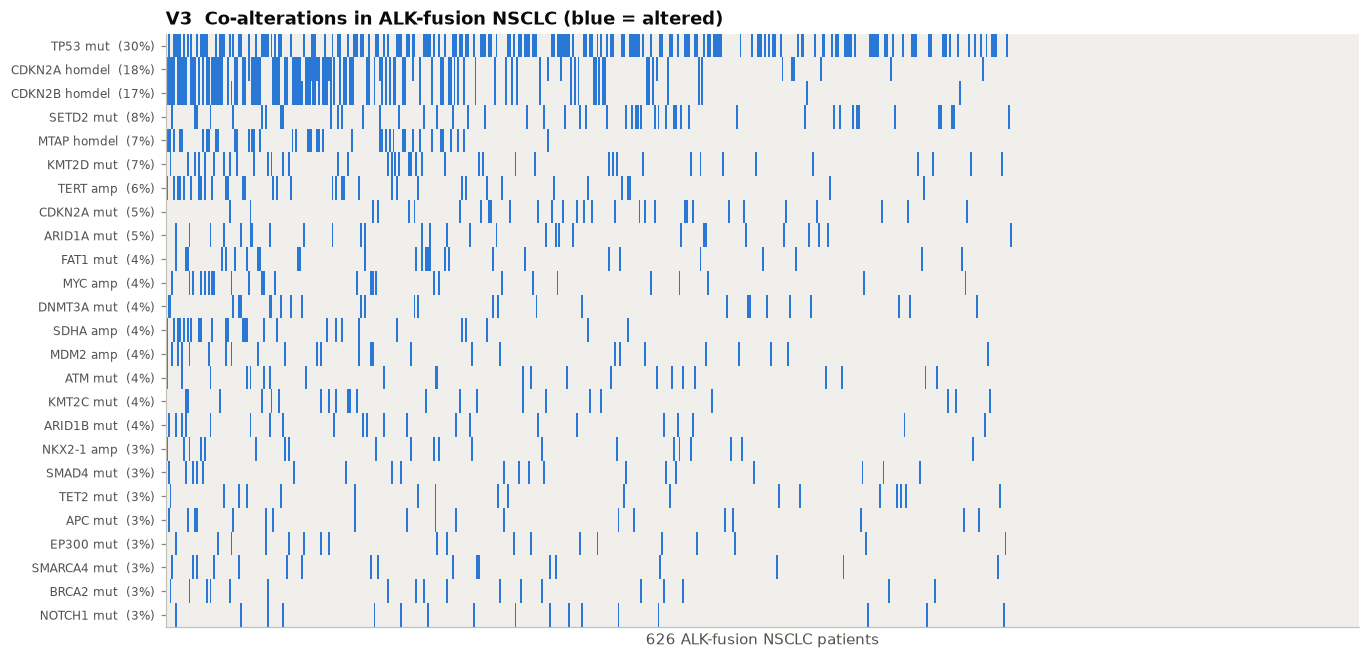

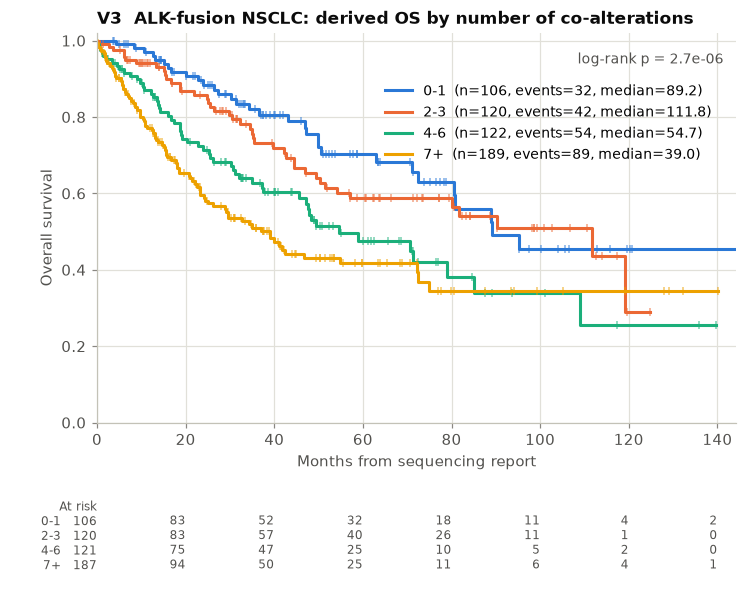

In [5]:
sid2pid = nsclc.set_index("sample_id").patient_id
prof_mut = mut_long.assign(patient_id=mut_long.sample_id.map(sid2pid)).dropna(subset=["patient_id"]).groupby("patient_id").apply(
    lambda d: "; ".join(sorted(f"{g} {p}" for g, p in zip(d.gene, d.HGVSp_Short.fillna("")))))
prof_sv = sv_long.assign(patient_id=sv_long.sample_id.map(sid2pid)).dropna(subset=["patient_id"]).groupby("patient_id").apply(
    lambda d: "; ".join(sorted(set(d.detail.fillna(d.gene).astype(str)))))
cna2 = cna_long[cna_long.value.abs() == 2].assign(patient_id=cna_long.sample_id.map(sid2pid)).dropna(subset=["patient_id"])
prof_cna = cna2.groupby("patient_id").apply(lambda d: "; ".join(sorted(f"{g} {'amp' if v == 2 else 'homdel'}" for g, v in zip(d.gene, d.value))))
profiles = pd.DataFrame({"mutations": prof_mut, "structural_variants": prof_sv, "copy_number": prof_cna}).reindex(A.patients).fillna("")
profiles = profiles.join(Sn[["time", "event", "cancer_type", "oncotree", "center", "age_seq_years"]], how="left")
cb.save(DS, "V3", table=profiles, slug="per_patient_profiles")
display(profiles.head(10))
example = A.status("ALK", "fus") & A.status("TP53") & (A.status("ERBB2", "amp"))
print(f"patients with EML4/ALK fusion + TP53 mut + ERBB2 amp: {int(example.sum())}; + STAT3 mut: {int((example & A.status('STAT3')).sum())}; + EPHA3 mut: {int((example & A.status('EPHA3')).sum())}")
# oncoprint-style matrix of the top co-alterations
fq = A.frequency(kinds=("mut", "amp", "homdel", "fus")).query("gene != 'ALK'").head(25)
feats = [(r.gene, r.kind) for r in fq.itertuples()]
M = pd.DataFrame({f"{g} {k}": A.matrix(k)[g] for g, k in feats}).astype(int)
M = M.loc[M.sum(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(14, 7))
ax.imshow(M.T.values, aspect="auto", cmap=plt.matplotlib.colors.ListedColormap(["#f0efec", cb.PALETTE[0]]), interpolation="nearest")
ax.set_yticks(range(len(M.columns))); ax.set_yticklabels([f"{c}  ({100 * M[c].mean():.0f}%)" for c in M.columns], fontsize=8)
ax.set_xticks([]); ax.set_xlabel(f"{len(M)} ALK-fusion NSCLC patients"); ax.grid(False)
ax.set_title("V3  Co-alterations in ALK-fusion NSCLC (blue = altered)", loc="left", fontweight="bold")
cb.save(DS, "V3", fig=fig, slug="oncoprint_top25")
# number of co-alterations vs OS
Sn["n_coalt"] = (A.matrix("alt").drop(columns="ALK", errors="ignore") & A.tested_for("alt").drop(columns="ALK", errors="ignore")).sum(axis=1).reindex(Sn.index)
Sn["coalt_group"] = pd.cut(Sn.n_coalt, [-1, 1, 3, 6, 1000], labels=["0-1", "2-3", "4-6", "7+"]).astype(str)
ax, t3 = cb.km_plot(Sn, "coalt_group", order=["0-1", "2-3", "4-6", "7+"], title="V3  ALK-fusion NSCLC: derived OS by number of co-alterations", xlabel="Months from sequencing report")
cb.save(DS, "V3", table=t3, fig=ax.figure, slug="os_by_n_coalterations")
display(t3)
cb.finding("V3", "descriptive",
           f"Per-patient profiles written for {len(profiles)} ALK-fusion NSCLC patients. Most frequent co-alterations: " +
           ", ".join(f"{r.gene} {r.kind} {r.pct}%" for r in fq.head(6).itertuples()) + f". OS by co-alteration burden: log-rank p={cb.fmt_p(t3.p_logrank[0])}.", F)

## V4 — No treatment data in v20: can treatments be identified another way?
Three indirect routes, each quantified below:
1. **Linkage to GENIE BPC.** BPC patients keep their GENIE IDs, so every ALK-altered BPC NSCLC patient has full regimen data (the Guardant-style ~300-patient study would be a comparable size).
2. **Resistance mutations as a footprint of prior ALK TKI** (G1202R, L1196M, I1171x, F1174x, G1269A, C1156Y, L1198F …): their presence implies the sample was taken after TKI exposure.
3. **Sample context**: sample type (primary vs metastasis), sequencing year (crizotinib approved 2011, alectinib 2015, lorlatinib 2018), and age.

ALK-fusion NSCLC patients also in BPC NSCLC (full treatment history available): 49 of 53 BPC ALK-fusion patients


regimen_drugs
True     41
False     7
Name: BPC ALK-fusion patients with an ALK TKI regimen, dtype: int64

regimen_drugs
Alectinib                          34
Crizotinib                         32
Brigatinib                         11
Lorlatinib                          7
Ceritinib                           6
Alectinib, Bevacizumab              2
Alectinib, Investigational Drug     1
Bevacizumab, Crizotinib             1
Name: count, dtype: int64

ALK-fusion NSCLC samples carrying a known ALK-TKI resistance mutation: 48 of 626 (7.7%)


HGVSp_Short
p.G1202R    17
p.L1196M    12
p.I1171N     5
p.G1269A     4
p.I1171T     3
p.F1174L     3
p.D1203N     3
p.I1171S     3
p.C1156Y     2
p.F1174C     2
Name: count, dtype: int64

resistance_mut,no,resistance mutation,All
sequencing year,,,
2013,3,0,3
2014,26,1,27
2015,34,3,37
2016,47,2,49
2017,45,6,51
2018,45,1,46
2019,63,2,65
2020,38,6,44
2021,56,8,64


,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank,HR,HR_lo,HR_hi,p_cox
0,no resistance mutation,496,194,79,0.883,0.761,0.547,8.7e-06,NaN,NaN,NaN,NaN
1,ALK resistance mutation (post-TKI footprint),41,23,23.2,0.729,0.477,0.197,8.7e-06,2.56,1.62,4.05,5.79e-05


[V4] partially feasible: Treatment cannot be recovered from v20 itself. Indirect handles: 48 samples carry an ALK-TKI resistance mutation (post-TKI footprint; derived OS HR 2.56); the BPC NSCLC release carries full regimen histories for its ALK-altered patients (see linkage count above); sample type and sequencing year give treatment-era context.


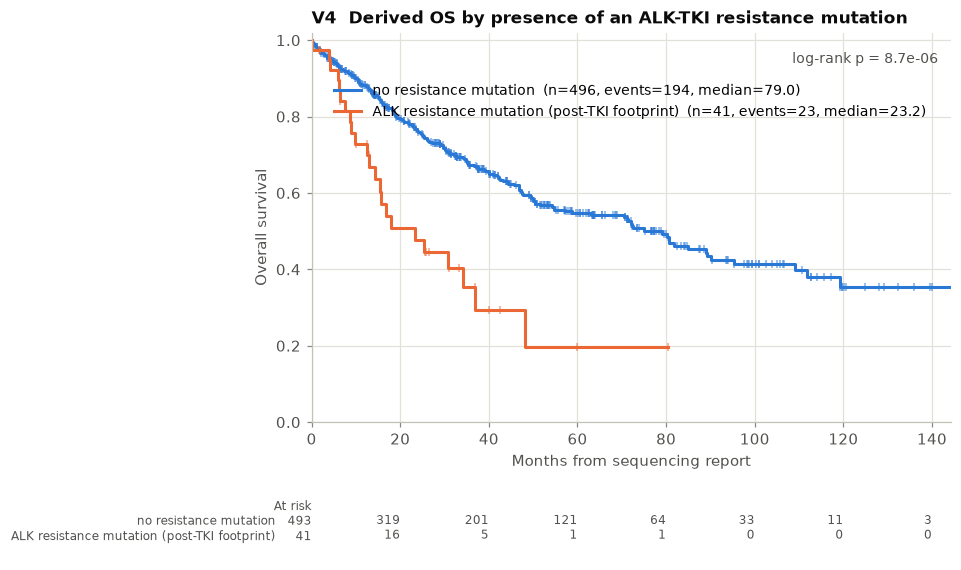

In [6]:
try:
    bpc_alk = alk_bpc.index[alk_bpc]
    overlap = Sn.index.intersection(bpc_alk)
    print(f"ALK-fusion NSCLC patients also in BPC NSCLC (full treatment history available): {len(overlap)} of {len(bpc_alk)} BPC ALK-fusion patients")
    rg = bn.regimens[bn.regimens.record_id.isin(bpc_alk)]
    display(cb.contains_any(rg.regimen_drugs, cb.ALK_TKI).groupby(rg.record_id).any().value_counts().rename("BPC ALK-fusion patients with an ALK TKI regimen"))
    display(rg[cb.contains_any(rg.regimen_drugs, cb.ALK_TKI)].regimen_drugs.value_counts().head(8))
except Exception as e:
    print("BPC NSCLC linkage unavailable:", e)
res_pat = r"G1202R|L1196M|I1171[A-Z]|F1174[A-Z]|G1269A|C1156Y|L1198F|D1203N|S1206[A-Z]|E1210K|F1245[A-Z]|G1128A|T1151|L1152[A-Z]"
alk_mut = alk["mut"][alk["mut"].sample_id.isin(nsclc.sample_id)]
resist = alk_mut[alk_mut.HGVSp_Short.fillna("").str.contains(res_pat, regex=True)]
print(f"ALK-fusion NSCLC samples carrying a known ALK-TKI resistance mutation: {resist.sample_id.nunique()} of {len(nsclc)} ({100 * resist.sample_id.nunique() / len(nsclc):.1f}%)")
display(resist.HGVSp_Short.value_counts().head(10))
Sn["resistance_mut"] = Sn.sample_id.isin(resist.sample_id)
display(pd.crosstab(Sn.seq_year.astype("Int64").astype(str), Sn.resistance_mut, margins=True).rename(columns={False: "no", True: "resistance mutation"}).rename_axis(index="sequencing year"))
d, t4 = cb.compare(Sn, Sn.resistance_mut, labels=("no resistance mutation", "ALK resistance mutation (post-TKI footprint)"), adjust=ADJ)
ax, _ = cb.km_plot(d, "group", order=["no resistance mutation", "ALK resistance mutation (post-TKI footprint)"], title="V4  Derived OS by presence of an ALK-TKI resistance mutation", xlabel="Months from sequencing report")
cb.save(DS, "V4", table=t4, fig=ax.figure, slug="resistance_footprint")
display(t4)
cb.finding("V4", "partially feasible",
           f"Treatment cannot be recovered from v20 itself. Indirect handles: {resist.sample_id.nunique()} samples carry an ALK-TKI resistance mutation (post-TKI footprint; derived OS HR {t4.attrs['HR']:.2f}); "
           f"the BPC NSCLC release carries full regimen histories for its ALK-altered patients (see linkage count above); sample type and sequencing year give treatment-era context.", F)

## Summary of findings

In [7]:
fd = pd.DataFrame(F)
cb.save(DS, "findings", table=fd)
pd.set_option("display.max_colwidth", 400)
fd

,question,verdict,note
0,V1,feasible with caveats,OS from sequencing report is derivable for 772 of 953 ALK-fusion patients (vital status + intervals released). Diagnosis date cannot be inferred; in BPC NSCLC the diagnosis-to-sequencing lag is months to years and varies by stage. Median derived OS: NSCLC 72.4 mo.
1,V2,signal,"ALK-fusion NSCLC n=537. FDR<0.1: KMT2D mut (n=37) HR 2.21 q=0.0014, TP53 mut (n=166) HR 1.69 q=0.0021, EGFR mut (n=13) HR 2.87 q=0.0022, NF2 mut (n=13) HR 3.48 q=0.008, CDKN2A homdel (n=96) HR 1.74 q=0.022, CDKN2B homdel (n=88) HR 1.63 q=0.053, MTAP homdel (n=30) HR 2.60 q=0.053, ROS1 mut (n=12) HR 2.63 q=0.09."
2,V3,descriptive,"Per-patient profiles written for 626 ALK-fusion NSCLC patients. Most frequent co-alterations: TP53 mut 30.0%, CDKN2A homdel 21.8%, CDKN2B homdel 19.7%, SETD2 mut 8.2%, MTAP homdel 8.0%, KMT2D mut 6.7%. OS by co-alteration burden: log-rank p=2.7e-06."
3,V4,partially feasible,Treatment cannot be recovered from v20 itself. Indirect handles: 48 samples carry an ALK-TKI resistance mutation (post-TKI footprint; derived OS HR 2.56); the BPC NSCLC release carries full regimen histories for its ALK-altered patients (see linkage count above); sample type and sequencing year give treatment-era context.
